In [3]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/piyalbaray111/mall-customers/Mall_Customers.csv


# **step: 0**

In [4]:

# Import NumPy for numerical calculations
import numpy as np

# Import Pandas for data loading and manipulation
import pandas as pd

# Import Matplotlib for data visualization
import matplotlib.pyplot as plt

# Import Seaborn for statistical data visualization
import seaborn as sns

# Import KMeans for customer clustering
from sklearn.cluster import KMeans

# Import StandardScaler for feature scaling
from sklearn.preprocessing import StandardScaler

# Import Silhouette Score for model evaluation
from sklearn.metrics import silhouette_score

# Import Warnings to control unnecessary warning messages
import warnings
warnings.filterwarnings('ignore')

# Print a success message
print("All Libraries Imported Successfully!")


All Libraries Imported Successfully!


In [5]:

# Load the Mall Customer dataset using Pandas
df = pd.read_csv('/kaggle/input/datasets/piyalbaray111/mall-customers/Mall_Customers.csv')

# Display the first five rows of the dataset
df.head()


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


# **step : 01**

In [6]:

# Check the number of rows and columns in the dataset
print("Dataset Shape:", df.shape)

# Display the total number of rows
print("Total Rows:", df.shape[0])

# Display the total number of columns
print("Total Columns:", df.shape[1])


Dataset Shape: (200, 5)
Total Rows: 200
Total Columns: 5


In [7]:
# Display all column names in the dataset
print(df.columns)


Index(['CustomerID', 'Gender', 'Age', 'Annual Income (k$)',
       'Spending Score (1-100)'],
      dtype='object')


In [8]:
# Display dataset information including data types and non-null values
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [9]:

# Generate statistical summary of numerical columns
df.describe()


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [11]:

# Display the first five rows of the dataset
print("First Five Rows:")
display(df.head())

# Display the last five rows of the dataset
print("Last Five Rows:")
display(df.tail())


First Five Rows:


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


Last Five Rows:


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
195,196,Female,35,120,79
196,197,Female,45,126,28
197,198,Male,32,126,74
198,199,Male,32,137,18
199,200,Male,30,137,83


# **step : 02**

In [12]:

# Check the total number of missing values in each column
print("Missing Values:")
print(df.isnull().sum())


Missing Values:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


In [13]:

# Count the total number of duplicate rows
print("Total Duplicate Rows:", df.duplicated().sum())


Total Duplicate Rows: 0


In [14]:

# Check the data types of all columns
print(df.dtypes)


CustomerID                 int64
Gender                    object
Age                        int64
Annual Income (k$)         int64
Spending Score (1-100)     int64
dtype: object


In [15]:

# Display the number of unique values in each column
print("Unique Values:")
print(df.nunique())


Unique Values:
CustomerID                200
Gender                      2
Age                        51
Annual Income (k$)         64
Spending Score (1-100)     84
dtype: int64


# **Step 3: Exploratory Data Analysis (EDA)**

Gender
Female    112
Male       88
Name: count, dtype: int64


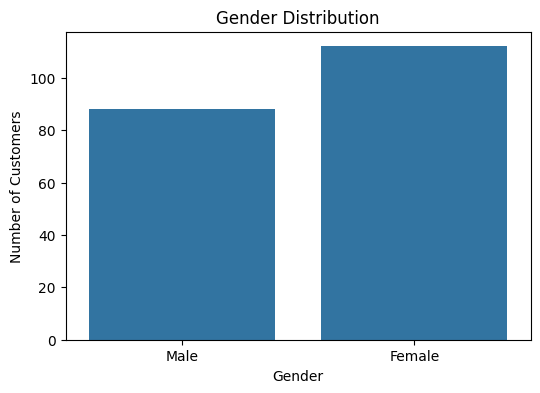

In [16]:

# Count the number of customers in each gender category
print(df['Gender'].value_counts())

# Visualize the gender distribution using a count plot
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Gender')

# Add chart title and axis labels
plt.title('Gender Distribution')
plt.xlabel('Gender')
plt.ylabel('Number of Customers')

# Display the chart
plt.show()


count    200.000000
mean      38.850000
std       13.969007
min       18.000000
25%       28.750000
50%       36.000000
75%       49.000000
max       70.000000
Name: Age, dtype: float64


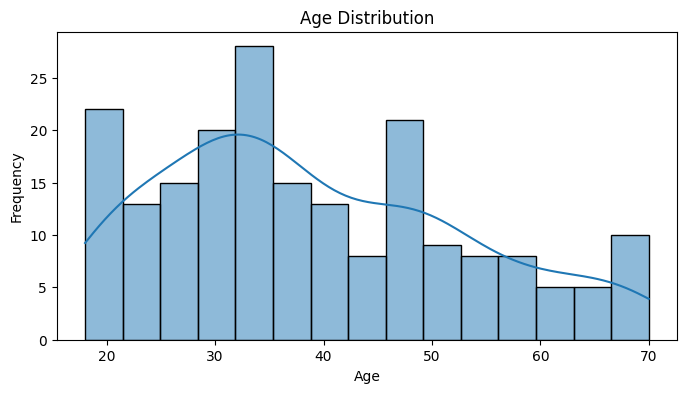

In [17]:

# Display the statistical distribution of customer ages
print(df['Age'].describe())

# Create a histogram to visualize age distribution
plt.figure(figsize=(8, 4))
sns.histplot(data=df, x='Age', bins=15, kde=True)

# Add chart title and axis labels
plt.title('Age Distribution')
plt.xlabel('Age')
plt.ylabel('Frequency')

# Display the chart
plt.show()


count    200.000000
mean      60.560000
std       26.264721
min       15.000000
25%       41.500000
50%       61.500000
75%       78.000000
max      137.000000
Name: Annual Income (k$), dtype: float64


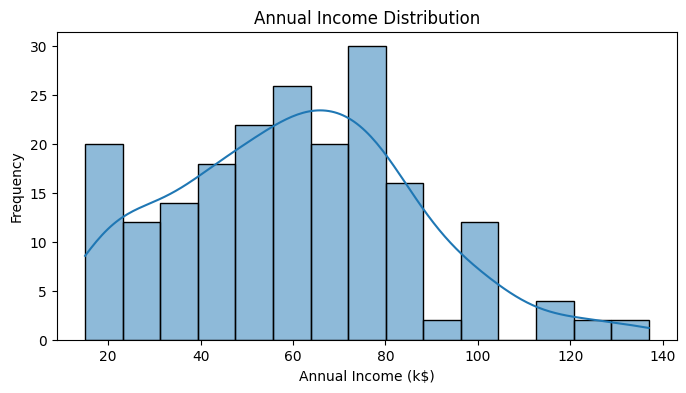

In [18]:

# Display statistical information about annual income
print(df['Annual Income (k$)'].describe())

# Visualize annual income distribution
plt.figure(figsize=(8, 4))
sns.histplot(data=df, x='Annual Income (k$)', bins=15, kde=True)

# Add chart title and axis labels
plt.title('Annual Income Distribution')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Frequency')

# Display the chart
plt.show()


count    200.000000
mean      50.200000
std       25.823522
min        1.000000
25%       34.750000
50%       50.000000
75%       73.000000
max       99.000000
Name: Spending Score (1-100), dtype: float64


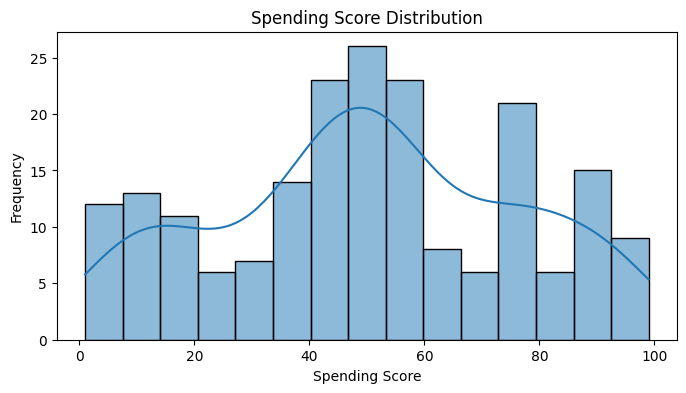

In [19]:

# Display statistical information about spending scores
print(df['Spending Score (1-100)'].describe())

# Visualize spending score distribution
plt.figure(figsize=(8, 4))
sns.histplot(data=df, x='Spending Score (1-100)', bins=15, kde=True)

# Add chart title and axis labels
plt.title('Spending Score Distribution')
plt.xlabel('Spending Score')
plt.ylabel('Frequency')

# Display the chart
plt.show()


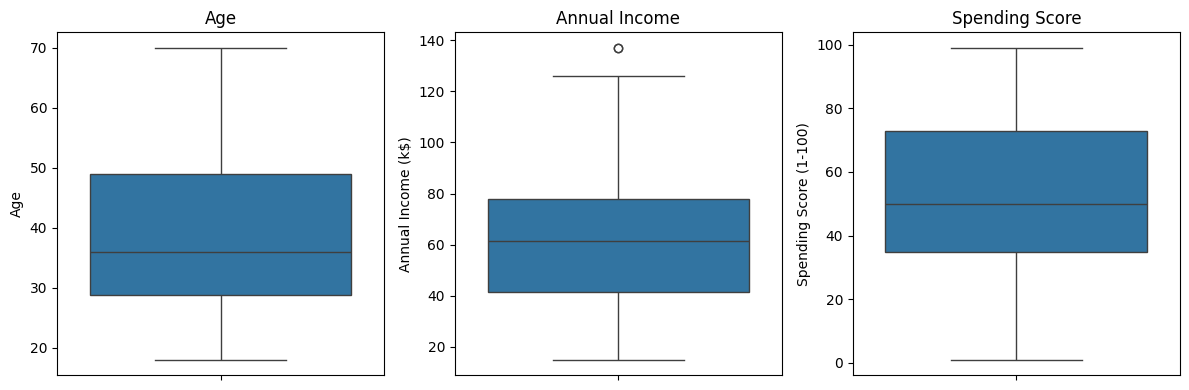

In [20]:

# Create boxplots to identify possible outliers
plt.figure(figsize=(12, 4))

# Plot the age distribution
plt.subplot(1, 3, 1)
sns.boxplot(y=df['Age'])
plt.title('Age')

# Plot the annual income distribution
plt.subplot(1, 3, 2)
sns.boxplot(y=df['Annual Income (k$)'])
plt.title('Annual Income')

# Plot the spending score distribution
plt.subplot(1, 3, 3)
sns.boxplot(y=df['Spending Score (1-100)'])
plt.title('Spending Score')

# Adjust the layout and display all plots
plt.tight_layout()
plt.show()


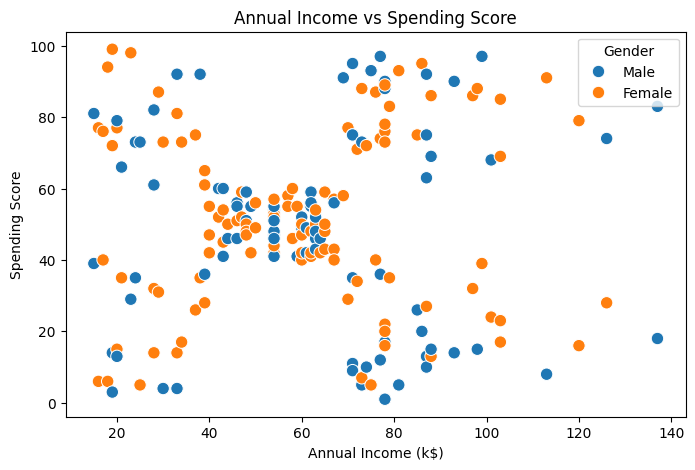

In [21]:

# Create a scatter plot to analyze income and spending relationships
plt.figure(figsize=(8, 5))

# Visualize annual income against spending score
sns.scatterplot(
    data=df,
    x='Annual Income (k$)',
    y='Spending Score (1-100)',
    hue='Gender',
    s=80
)

# Add chart title and axis labels
plt.title('Annual Income vs Spending Score')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score')

# Display the chart
plt.show()


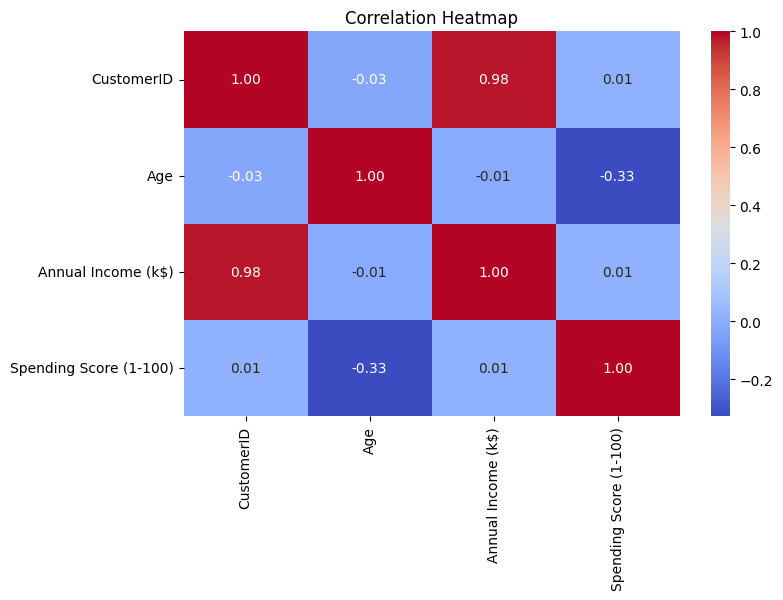

In [22]:

# Select numerical columns for correlation analysis
numeric_df = df.select_dtypes(include=np.number)

# Calculate the correlation matrix
correlation = numeric_df.corr()

# Create a heatmap to visualize correlations
plt.figure(figsize=(8, 5))
sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

# Add chart title
plt.title('Correlation Heatmap')

# Display the heatmap
plt.show()


# **step : 04(Work with outlier)**

In [23]:
# Calculate the first quartile (25th percentile)
Q1 = df['Annual Income (k$)'].quantile(0.25)

# Calculate the third quartile (75th percentile)
Q3 = df['Annual Income (k$)'].quantile(0.75)

# Calculate the interquartile range
IQR = Q3 - Q1

# Calculate the lower and upper outlier boundaries
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Identify outliers in the annual income column
outliers = df[
    (df['Annual Income (k$)'] < lower_bound) |
    (df['Annual Income (k$)'] > upper_bound)
]

# Display the outlier boundaries and count
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print("Total Outliers:", len(outliers))

# Display the outlier records
display(outliers)

Lower Bound: -13.25
Upper Bound: 132.75
Total Outliers: 2


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
198,199,Male,32,137,18
199,200,Male,30,137,83


In [24]:
# Import NumPy for logarithmic transformation
import numpy as np

# Create a new column using log transformation
df['Annual Income Log'] = np.log1p(df['Annual Income (k$)'])

# Display the original and transformed income columns
display(df[['Annual Income (k$)', 'Annual Income Log']].head())

,Annual Income (k$),Annual Income Log
0,15,2.772589
1,15,2.772589
2,16,2.833213
3,16,2.833213
4,17,2.890372


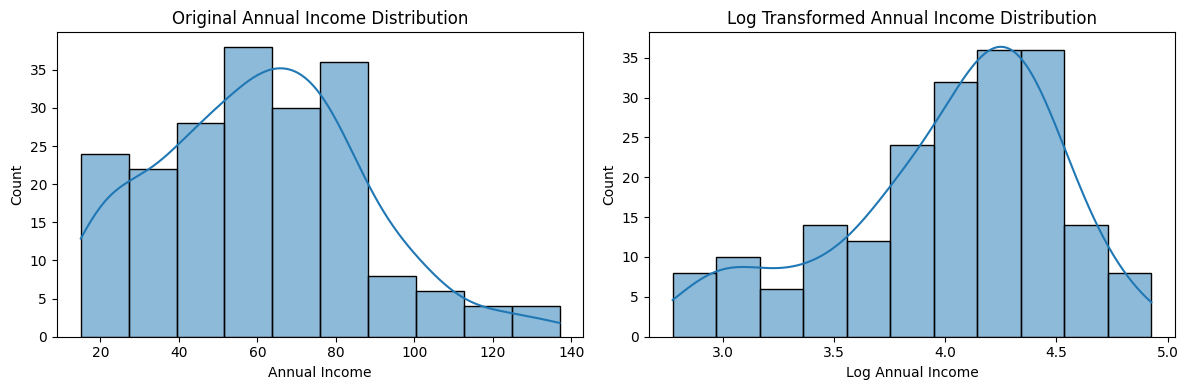

In [25]:
# Create two plots to compare original and transformed distributions
plt.figure(figsize=(12, 4))

# Display the original annual income distribution
plt.subplot(1, 2, 1)
sns.histplot(df['Annual Income (k$)'], kde=True)
plt.title('Original Annual Income Distribution')
plt.xlabel('Annual Income')

# Display the log-transformed annual income distribution
plt.subplot(1, 2, 2)
sns.histplot(df['Annual Income Log'], kde=True)
plt.title('Log Transformed Annual Income Distribution')
plt.xlabel('Log Annual Income')

# Adjust spacing and display both plots
plt.tight_layout()
plt.show()

# **Step : 05**

In [26]:
# Select numerical features for customer segmentation
X = df[['Age', 'Annual Income (k$)', 'Spending Score (1-100)']]

# Display the selected features
display(X.head())

# Display the shape of selected features
print("Selected Features Shape:", X.shape)

,Age,Annual Income (k$),Spending Score (1-100)
0,19,15,39
1,21,15,81
2,20,16,6
3,23,16,77
4,31,17,40


Selected Features Shape: (200, 3)


In [27]:
# Create a StandardScaler object
scaler = StandardScaler()

# Fit the scaler and transform the selected features
X_scaled = scaler.fit_transform(X)

# Convert the scaled array into a DataFrame
X_scaled = pd.DataFrame(X_scaled, columns=X.columns)

# Display the first five rows of scaled data
display(X_scaled.head())

# Display the shape of scaled data
print("Scaled Data Shape:", X_scaled.shape)

,Age,Annual Income (k$),Spending Score (1-100)
0,-1.424569,-1.738999,-0.434801
1,-1.281035,-1.738999,1.195704
2,-1.352802,-1.700830,-1.715913
3,-1.137502,-1.700830,1.040418
4,-0.563369,-1.662660,-0.395980


Scaled Data Shape: (200, 3)


In [28]:
# Display statistical information before scaling
print("Before Scaling:")
display(X.describe())

# Display statistical information after scaling
print("After Scaling:")
display(X_scaled.describe())

Before Scaling:


,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000
mean,38.850000,60.560000,50.200000
std,13.969007,26.264721,25.823522
min,18.000000,15.000000,1.000000
25%,28.750000,41.500000,34.750000
50%,36.000000,61.500000,50.000000
75%,49.000000,78.000000,73.000000
max,70.000000,137.000000,99.000000


After Scaling:


,Age,Annual Income (k$),Spending Score (1-100)
count,2.000000e+02,2.000000e+02,2.000000e+02
mean,-1.021405e-16,-2.131628e-16,-1.465494e-16
std,1.002509e+00,1.002509e+00,1.002509e+00
min,-1.496335e+00,-1.738999e+00,-1.910021e+00
25%,-7.248436e-01,-7.275093e-01,-5.997931e-01
50%,-2.045351e-01,3.587926e-02,-7.764312e-03
75%,7.284319e-01,6.656748e-01,8.851316e-01
max,2.235532e+00,2.917671e+00,1.894492e+00


# **step : 06**

In [31]:
# Create a KMeans clustering model with 5 clusters
kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

# Train the KMeans model using scaled features
kmeans.fit(X_scaled)

# Predict the cluster labels for all customers
kmeans_labels = kmeans.labels_

# Display the cluster labels
print("Cluster Labels:")
print(kmeans_labels)

# Display the number of clusters created
print("Number of Clusters:", len(np.unique(kmeans_labels)))

Cluster Labels:
[1 1 0 1 1 1 0 1 0 1 0 1 0 1 0 1 0 1 0 1 0 1 0 1 0 1 0 1 0 1 0 1 0 1 0 1 0
 1 0 1 4 1 0 1 0 1 4 1 1 1 4 1 1 4 4 4 4 4 1 4 4 1 4 4 4 1 4 4 1 1 4 4 4 4
 4 1 4 4 1 4 4 1 4 4 1 4 4 1 1 4 4 1 4 4 1 1 4 1 4 1 1 4 4 1 4 1 4 4 4 4 4
 1 3 1 1 1 4 4 4 4 1 3 2 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2
 3 2 3 2 3 2 3 2 3 2 3 2 4 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3
 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2]
Number of Clusters: 5


In [33]:
# Create a copy of the original dataset
kmeans_df = df.copy()

# Add the predicted cluster labels to the dataset
kmeans_df['KMeans_Cluster'] = kmeans_labels

# Display the first five rows with cluster labels
display(kmeans_df.head())

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Annual Income Log,KMeans_Cluster
0,1,Male,19,15,39,2.772589,1
1,2,Male,21,15,81,2.772589,1
2,3,Female,20,16,6,2.833213,0
3,4,Female,23,16,77,2.833213,1
4,5,Female,31,17,40,2.890372,1


In [34]:
# Import additional clustering evaluation metrics
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

# Calculate the Silhouette Score
kmeans_silhouette = silhouette_score(X_scaled, kmeans_labels)

# Calculate the Davies-Bouldin Index
kmeans_db = davies_bouldin_score(X_scaled, kmeans_labels)

# Calculate the Calinski-Harabasz Score
kmeans_ch = calinski_harabasz_score(X_scaled, kmeans_labels)

# Display all evaluation scores
print("K-Means Evaluation Results")
print("--------------------------------")
print("Silhouette Score:", kmeans_silhouette)
print("Davies-Bouldin Index:", kmeans_db)
print("Calinski-Harabasz Score:", kmeans_ch)

K-Means Evaluation Results
--------------------------------
Silhouette Score: 0.41664341513732767
Davies-Bouldin Index: 0.874551051002418
Calinski-Harabasz Score: 125.10094020060954


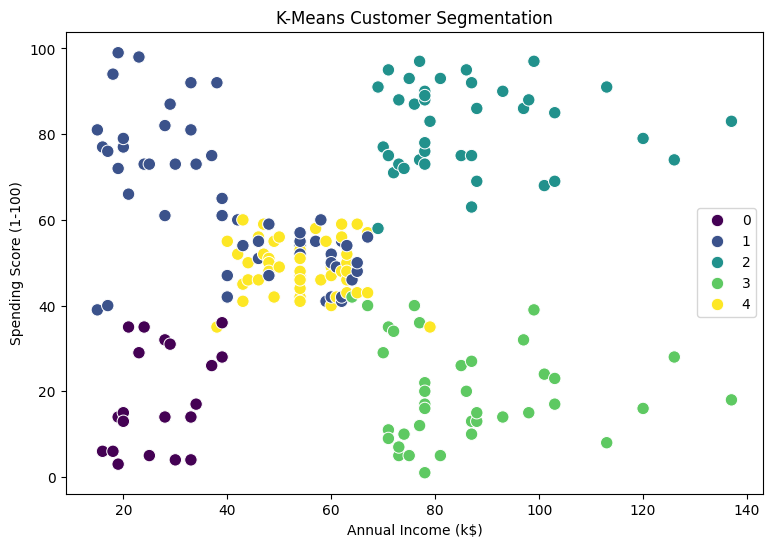

In [35]:
# Create a scatter plot for KMeans customer clusters
plt.figure(figsize=(9, 6))

# Visualize customers using annual income and spending score
sns.scatterplot(
    x=df['Annual Income (k$)'],
    y=df['Spending Score (1-100)'],
    hue=kmeans_labels,
    palette='viridis',
    s=80
)

# Add chart title and axis labels
plt.title('K-Means Customer Segmentation')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')

# Display the cluster visualization
plt.show()

# **next algo no :02 (Hierarchical)**

In [37]:
# Import AgglomerativeClustering from Scikit-learn
from sklearn.cluster import AgglomerativeClustering

# Create an Agglomerative Clustering model
hierarchical = AgglomerativeClustering(
    n_clusters=5,
    linkage='ward'
)

# Fit the model and predict cluster labels
hierarchical_labels = hierarchical.fit_predict(X_scaled)

# Display the cluster labels
print("Hierarchical Cluster Labels:")
print(hierarchical_labels)

# Display the number of clusters created
print("Number of Clusters:", len(np.unique(hierarchical_labels)))

Hierarchical Cluster Labels:
[4 0 4 0 4 0 4 0 4 0 4 0 4 0 4 0 4 0 4 0 4 0 4 0 4 0 4 0 4 0 4 0 4 0 4 0 4
 0 4 0 1 0 4 0 4 0 1 0 0 0 1 0 0 1 1 1 1 1 0 1 1 0 1 1 1 0 0 1 0 0 1 1 1 1
 1 0 0 0 0 1 1 0 1 1 0 1 1 0 0 1 1 0 1 0 0 0 1 0 1 0 0 1 1 0 1 0 1 1 1 1 1
 0 0 0 0 0 1 1 1 1 0 0 0 2 0 2 1 2 3 2 3 2 0 2 0 2 3 2 0 2 3 2 0 2 0 2 1 2
 3 2 3 2 3 2 3 2 3 2 3 2 1 2 0 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2 3
 2 3 2 3 2 3 2 3 2 3 2 3 2 3 2]
Number of Clusters: 5


In [38]:
# Create a copy of the original dataset
hierarchical_df = df.copy()

# Add Hierarchical cluster labels to the dataset
hierarchical_df['Hierarchical_Cluster'] = hierarchical_labels

# Display the first five rows
display(hierarchical_df.head())

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Annual Income Log,Hierarchical_Cluster
0,1,Male,19,15,39,2.772589,4
1,2,Male,21,15,81,2.772589,0
2,3,Female,20,16,6,2.833213,4
3,4,Female,23,16,77,2.833213,0
4,5,Female,31,17,40,2.890372,4


In [39]:
# Calculate the Silhouette Score
hierarchical_silhouette = silhouette_score(
    X_scaled, hierarchical_labels
)

# Calculate the Davies-Bouldin Index
hierarchical_db = davies_bouldin_score(
    X_scaled, hierarchical_labels
)

# Calculate the Calinski-Harabasz Score
hierarchical_ch = calinski_harabasz_score(
    X_scaled, hierarchical_labels
)

# Display all evaluation scores
print("Hierarchical Clustering Evaluation Results")
print("--------------------------------------------")
print("Silhouette Score:", hierarchical_silhouette)
print("Davies-Bouldin Index:", hierarchical_db)
print("Calinski-Harabasz Score:", hierarchical_ch)

Hierarchical Clustering Evaluation Results
--------------------------------------------
Silhouette Score: 0.39002826186267214
Davies-Bouldin Index: 0.9162886109753661
Calinski-Harabasz Score: 107.82656032570374


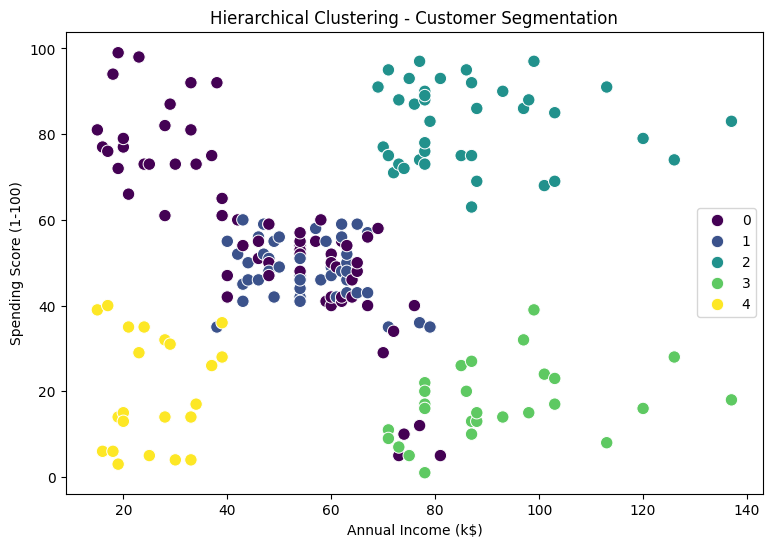

In [40]:
# Create a figure for cluster visualization
plt.figure(figsize=(9, 6))

# Plot customers using annual income and spending score
sns.scatterplot(
    x=df['Annual Income (k$)'],
    y=df['Spending Score (1-100)'],
    hue=hierarchical_labels,
    palette='viridis',
    s=80
)

# Add chart title and axis labels
plt.title('Hierarchical Clustering - Customer Segmentation')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')

# Display the cluster visualization
plt.show()

In [41]:
# Store Hierarchical evaluation scores for final comparison
hierarchical_result = {
    'Algorithm': 'Hierarchical',
    'Silhouette Score': hierarchical_silhouette,
    'Davies-Bouldin Index': hierarchical_db,
    'Calinski-Harabasz Score': hierarchical_ch
}

# Display the evaluation result
print(hierarchical_result)

{'Algorithm': 'Hierarchical', 'Silhouette Score': np.float64(0.39002826186267214), 'Davies-Bouldin Index': np.float64(0.9162886109753661), 'Calinski-Harabasz Score': np.float64(107.82656032570374)}


# **algo :03 (DBSCAN)**

In [43]:
# Import DBSCAN from Scikit-learn
from sklearn.cluster import DBSCAN

# Create a DBSCAN clustering model
dbscan = DBSCAN(
    eps=0.8,
    min_samples=5
)

# Fit the DBSCAN model and predict cluster labels
dbscan_labels = dbscan.fit_predict(X_scaled)

# Display the cluster labels
print("DBSCAN Cluster Labels:")
print(dbscan_labels)

# Count the number of clusters, excluding noise label -1
dbscan_clusters = len(set(dbscan_labels) - {-1})

# Count the total number of noise points
dbscan_noise = list(dbscan_labels).count(-1)

# Display the number of clusters and noise points
print("Number of Clusters:", dbscan_clusters)
print("Number of Noise Points:", dbscan_noise)

DBSCAN Cluster Labels:
[-1  0 -1  0  0  0 -1  0  0  0  0 -1  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0
  0  0  0  0 -1  0 -1  0]
Number of Clusters: 1
Number of Noise Points: 6


In [44]:
# Create a copy of the original dataset
dbscan_df = df.copy()

# Add DBSCAN cluster labels to the dataset
dbscan_df['DBSCAN_Cluster'] = dbscan_labels

# Display the first five rows
display(dbscan_df.head())

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Annual Income Log,DBSCAN_Cluster
0,1,Male,19,15,39,2.772589,-1
1,2,Male,21,15,81,2.772589,0
2,3,Female,20,16,6,2.833213,-1
3,4,Female,23,16,77,2.833213,0
4,5,Female,31,17,40,2.890372,0


In [45]:
# Import clustering evaluation metrics
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

# Identify customers that are not classified as noise
dbscan_mask = dbscan_labels != -1

# Select scaled data and labels without noise points
dbscan_valid_X = X_scaled.loc[dbscan_mask]
dbscan_valid_labels = dbscan_labels[dbscan_mask]

# Check whether valid clusters are available for evaluation
if len(np.unique(dbscan_valid_labels)) >= 2:

    # Calculate the Silhouette Score
    dbscan_silhouette = silhouette_score(
        dbscan_valid_X, dbscan_valid_labels
    )

    # Calculate the Davies-Bouldin Index
    dbscan_db = davies_bouldin_score(
        dbscan_valid_X, dbscan_valid_labels
    )

    # Calculate the Calinski-Harabasz Score
    dbscan_ch = calinski_harabasz_score(
        dbscan_valid_X, dbscan_valid_labels
    )

    # Display all evaluation scores
    print("DBSCAN Evaluation Results")
    print("--------------------------------")
    print("Silhouette Score:", dbscan_silhouette)
    print("Davies-Bouldin Index:", dbscan_db)
    print("Calinski-Harabasz Score:", dbscan_ch)

else:
    # Display a message when valid cluster evaluation is not possible
    dbscan_silhouette = np.nan
    dbscan_db = np.nan
    dbscan_ch = np.nan

    print("DBSCAN cannot be evaluated with these parameters.")
    print("Try tuning eps or min_samples.")

DBSCAN cannot be evaluated with these parameters.
Try tuning eps or min_samples.


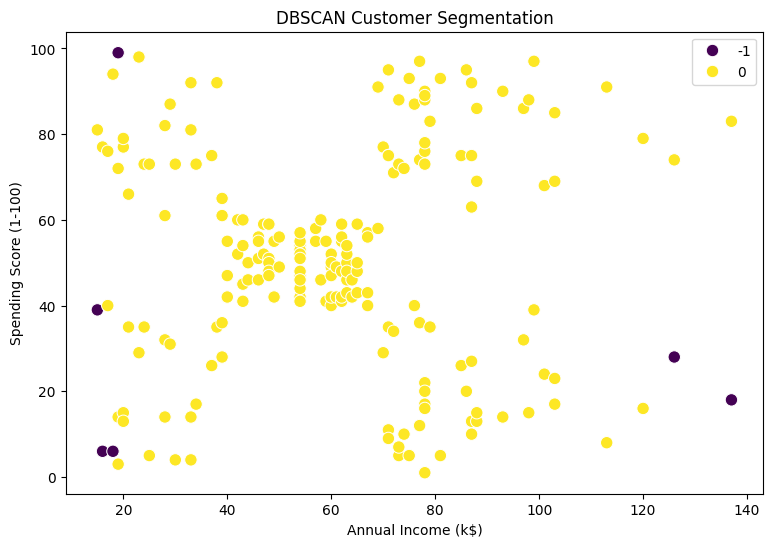

In [46]:
# Create a figure for DBSCAN cluster visualization
plt.figure(figsize=(9, 6))

# Plot customers using annual income and spending score
sns.scatterplot(
    x=df['Annual Income (k$)'],
    y=df['Spending Score (1-100)'],
    hue=dbscan_labels,
    palette='viridis',
    s=80
)

# Add chart title and axis labels
plt.title('DBSCAN Customer Segmentation')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')

# Display the cluster visualization
plt.show()

# **step : 07 ( Compare 3 Algorithms and Find Best Result)**

In [48]:
# Create a comparison DataFrame for all three algorithms
comparison_3 = pd.DataFrame([
    {
        'Algorithm': 'K-Means',
        'Silhouette Score': kmeans_silhouette,
        'Davies-Bouldin Index': kmeans_db,
        'Calinski-Harabasz Score': kmeans_ch
    },
    {
        'Algorithm': 'Hierarchical',
        'Silhouette Score': hierarchical_silhouette,
        'Davies-Bouldin Index': hierarchical_db,
        'Calinski-Harabasz Score': hierarchical_ch
    },
    {
        'Algorithm': 'DBSCAN',
        'Silhouette Score': dbscan_silhouette,
        'Davies-Bouldin Index': dbscan_db,
        'Calinski-Harabasz Score': dbscan_ch
    }
])

# Display the comparison table
print("CLUSTERING ALGORITHM COMPARISON")
display(comparison_3.round(4))


# Find the best algorithm based on each evaluation metric
best_silhouette = comparison_3.loc[
    comparison_3['Silhouette Score'].idxmax(), 'Algorithm'
]

best_db = comparison_3.loc[
    comparison_3['Davies-Bouldin Index'].idxmin(), 'Algorithm'
]

best_ch = comparison_3.loc[
    comparison_3['Calinski-Harabasz Score'].idxmax(), 'Algorithm'
]


# Display the best algorithm for each metric
print("\nBEST ALGORITHM BY EACH METRIC")
print("--------------------------------------")
print("Best Silhouette Score:", best_silhouette)
print("Best Davies-Bouldin Index:", best_db)
print("Best Calinski-Harabasz Score:", best_ch)


# Calculate the ranking of each algorithm for all three metrics
ranking = pd.DataFrame()

# Rank higher Silhouette Scores as better
ranking['Silhouette Rank'] = comparison_3['Silhouette Score'].rank(
    ascending=False, method='min', na_option='bottom'
)

# Rank lower Davies-Bouldin Index values as better
ranking['Davies-Bouldin Rank'] = comparison_3['Davies-Bouldin Index'].rank(
    ascending=True, method='min', na_option='bottom'
)

# Rank higher Calinski-Harabasz Scores as better
ranking['Calinski-Harabasz Rank'] = comparison_3['Calinski-Harabasz Score'].rank(
    ascending=False, method='min', na_option='bottom'
)

# Calculate the average rank for each algorithm
comparison_3['Average Rank'] = ranking.mean(axis=1)

# Find the algorithm with the lowest average rank
best_overall = comparison_3.loc[
    comparison_3['Average Rank'].idxmin(), 'Algorithm'
]

# Display the overall ranking
print("\nOVERALL ALGORITHM RANKING")
display(comparison_3[['Algorithm', 'Average Rank']].sort_values('Average Rank'))

# Display the overall best algorithm
print("\n======================================")
print("OVERALL BEST ALGORITHM:", best_overall)
print("======================================")

CLUSTERING ALGORITHM COMPARISON


,Algorithm,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Score
0,K-Means,0.4166,0.8746,125.1009
1,Hierarchical,0.3900,0.9163,107.8266
2,DBSCAN,NaN,NaN,NaN



BEST ALGORITHM BY EACH METRIC
--------------------------------------
Best Silhouette Score: K-Means
Best Davies-Bouldin Index: K-Means
Best Calinski-Harabasz Score: K-Means

OVERALL ALGORITHM RANKING


,Algorithm,Average Rank
0,K-Means,1.0
1,Hierarchical,2.0
2,DBSCAN,3.0



OVERALL BEST ALGORITHM: K-Means


# **Step : 08**

In [49]:
# Create an empty list to store Silhouette Scores
silhouette_scores = []

# Test different cluster numbers from 2 to 10
for k in range(2, 11):

    # Create a KMeans model with the current K value
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    # Fit the model and predict cluster labels
    labels = model.fit_predict(X_scaled)

    # Calculate the Silhouette Score
    score = silhouette_score(X_scaled, labels)

    # Store the K value and its Silhouette Score
    silhouette_scores.append(score)

# Display the Silhouette Scores
for k, score in zip(range(2, 11), silhouette_scores):
    print(f"K = {k}, Silhouette Score = {score:.4f}")

K = 2, Silhouette Score = 0.3355
K = 3, Silhouette Score = 0.3578
K = 4, Silhouette Score = 0.4040
K = 5, Silhouette Score = 0.4166
K = 6, Silhouette Score = 0.4284
K = 7, Silhouette Score = 0.4172
K = 8, Silhouette Score = 0.4082
K = 9, Silhouette Score = 0.4177
K = 10, Silhouette Score = 0.4066


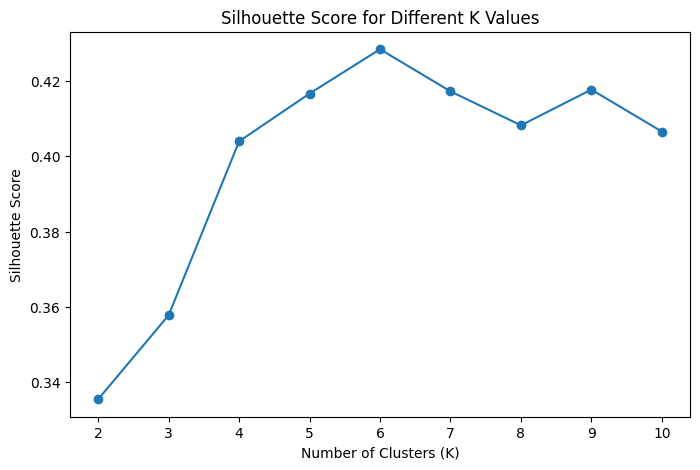

In [51]:
# Create a figure for Silhouette Score comparison
plt.figure(figsize=(8, 5))

# Plot the Silhouette Scores for different K values
plt.plot(range(2, 11), silhouette_scores, marker='o')

# Add chart title and axis labels
plt.title('Silhouette Score for Different K Values')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Silhouette Score')

# Display the graph
plt.show()

In [53]:
# Find the K value with the highest Silhouette Score
best_k = range(2, 11)[np.argmax(silhouette_scores)]

# Display the best K value
print("Best K Value:", best_k)

# Display the highest Silhouette Score
print("Best Silhouette Score:", max(silhouette_scores))

Best K Value: 6
Best Silhouette Score: 0.4284167762892593


# **step : 09**

In [54]:
# Create the final K-Means model using the best K value
final_kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)

# Train the final K-Means model on scaled data
final_kmeans.fit(X_scaled)

# Get the cluster labels for each customer
final_labels = final_kmeans.labels_

# Add the cluster labels to the original dataset
final_df = df.copy()
final_df['Cluster'] = final_labels

# Display the first five rows with cluster labels
display(final_df.head())

# Display the number of customers in each cluster
print(final_df['Cluster'].value_counts().sort_index())

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Annual Income Log,Cluster
0,1,Male,19,15,39,2.772589,4
1,2,Male,21,15,81,2.772589,4
2,3,Female,20,16,6,2.833213,5
3,4,Female,23,16,77,2.833213,4
4,5,Female,31,17,40,2.890372,5


Cluster
0    45
1    39
2    33
3    39
4    23
5    21
Name: count, dtype: int64


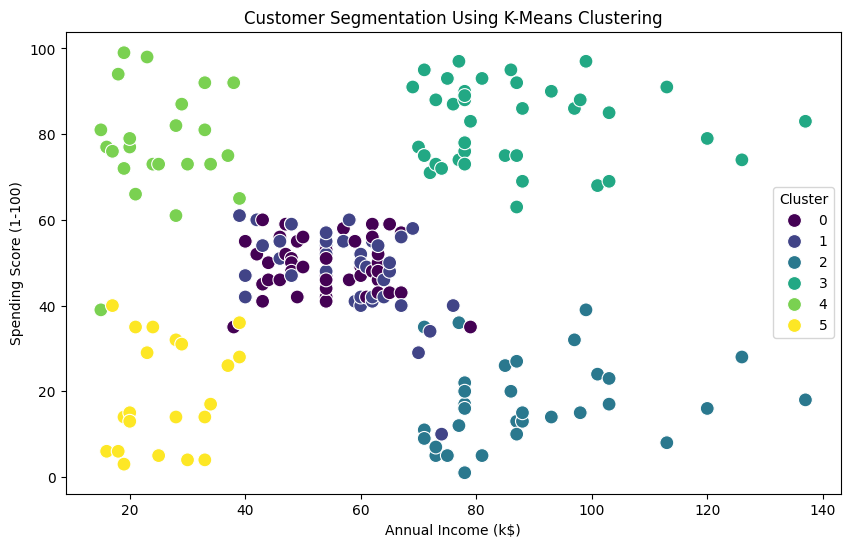

In [55]:
# Create a figure for the cluster visualization
plt.figure(figsize=(10, 6))

# Create a scatter plot using Annual Income and Spending Score
sns.scatterplot(
    data=final_df,
    x='Annual Income (k$)',
    y='Spending Score (1-100)',
    hue='Cluster',
    palette='viridis',
    s=100
)

# Add the graph title
plt.title('Customer Segmentation Using K-Means Clustering')

# Add labels to the X and Y axes
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')

# Display the legend
plt.legend(title='Cluster')

# Display the graph
plt.show()

# **step :10**

In [56]:
# Group customers by their cluster and calculate average feature values
cluster_analysis = final_df.groupby('Cluster').agg({
    'Age': 'mean',
    'Annual Income (k$)': 'mean',
    'Spending Score (1-100)': 'mean',
    'CustomerID': 'count'
})

# Rename the CustomerID column to Total Customers
cluster_analysis.rename(columns={'CustomerID': 'Total Customers'}, inplace=True)

# Round average values to two decimal places
cluster_analysis = cluster_analysis.round(2)

# Display the cluster analysis
display(cluster_analysis)

,Age,Annual Income (k$),Spending Score (1-100),Total Customers
Cluster,,,,
0,56.33,54.27,49.07,45
1,26.79,57.10,48.13,39
2,41.94,88.94,16.97,33
3,32.69,86.54,82.13,39
4,25.00,25.26,77.61,23
5,45.52,26.29,19.38,21


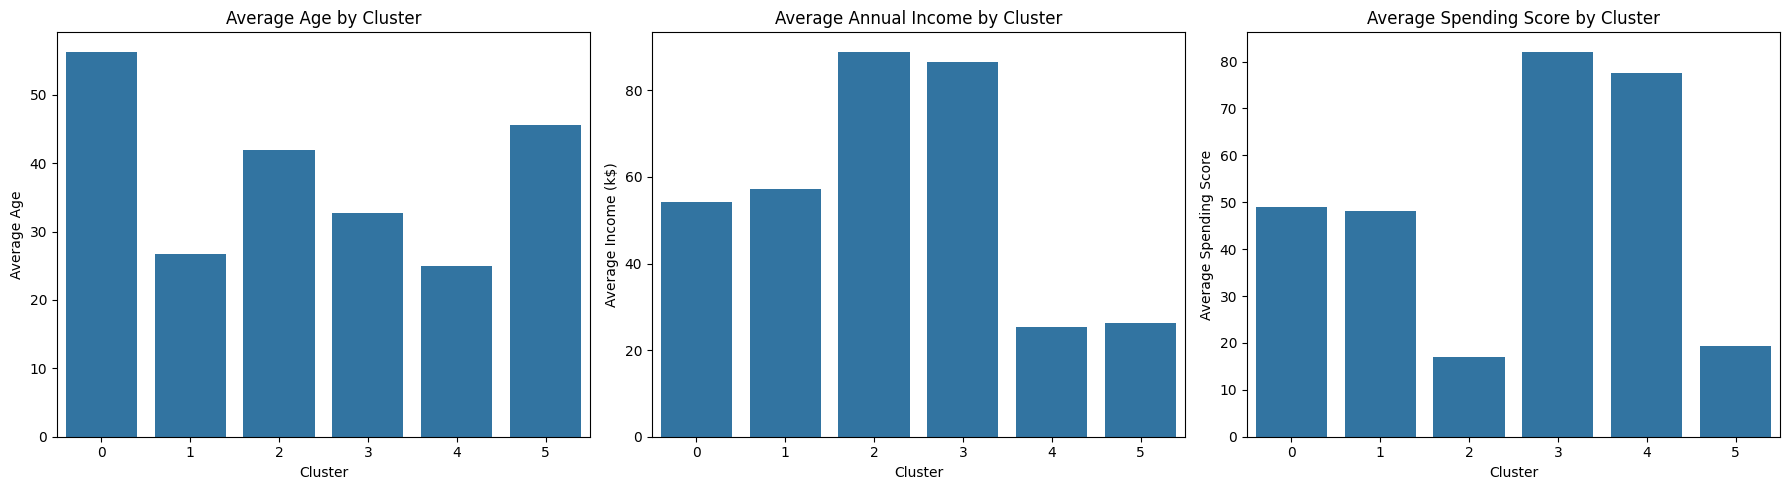

In [57]:
# Create a figure with three side-by-side bar charts
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot average Age for each cluster
sns.barplot(data=cluster_analysis, x=cluster_analysis.index, y='Age', ax=axes[0])
axes[0].set_title('Average Age by Cluster')
axes[0].set_xlabel('Cluster')
axes[0].set_ylabel('Average Age')

# Plot average Annual Income for each cluster
sns.barplot(data=cluster_analysis, x=cluster_analysis.index, y='Annual Income (k$)', ax=axes[1])
axes[1].set_title('Average Annual Income by Cluster')
axes[1].set_xlabel('Cluster')
axes[1].set_ylabel('Average Income (k$)')

# Plot average Spending Score for each cluster
sns.barplot(data=cluster_analysis, x=cluster_analysis.index, y='Spending Score (1-100)', ax=axes[2])
axes[2].set_title('Average Spending Score by Cluster')
axes[2].set_xlabel('Cluster')
axes[2].set_ylabel('Average Spending Score')

# Adjust spacing between charts
plt.tight_layout()

# Display all three charts
plt.show()

# **step : 11**

In [58]:
# Create an empty dictionary to store customer segment names
segment_names = {}

# Loop through each cluster to identify its customer segment
for cluster in cluster_analysis.index:

    # Get the average income of the current cluster
    income = cluster_analysis.loc[cluster, 'Annual Income (k$)']

    # Get the average spending score of the current cluster
    spending = cluster_analysis.loc[cluster, 'Spending Score (1-100)']

    # Assign a segment name based on income and spending score
    if income >= cluster_analysis['Annual Income (k$)'].median() and spending >= cluster_analysis['Spending Score (1-100)'].median():
        segment_names[cluster] = 'High Income - High Spending'

    elif income >= cluster_analysis['Annual Income (k$)'].median() and spending < cluster_analysis['Spending Score (1-100)'].median():
        segment_names[cluster] = 'High Income - Low Spending'

    elif income < cluster_analysis['Annual Income (k$)'].median() and spending >= cluster_analysis['Spending Score (1-100)'].median():
        segment_names[cluster] = 'Low Income - High Spending'

    else:
        segment_names[cluster] = 'Low Income - Low Spending'

# Add the segment names to the original customer data
final_df['Customer_Segment'] = final_df['Cluster'].map(segment_names)

# Display customer IDs, cluster numbers, and segment names
display(final_df[['CustomerID', 'Cluster', 'Customer_Segment']].head(10))

# Display the number of customers in each segment
print(final_df['Customer_Segment'].value_counts())

,CustomerID,Cluster,Customer_Segment
0,1,4,Low Income - High Spending
1,2,4,Low Income - High Spending
2,3,5,Low Income - Low Spending
3,4,4,Low Income - High Spending
4,5,5,Low Income - Low Spending
5,6,4,Low Income - High Spending
6,7,5,Low Income - Low Spending
7,8,4,Low Income - High Spending
8,9,5,Low Income - Low Spending
9,10,4,Low Income - High Spending


Customer_Segment
High Income - Low Spending     72
Low Income - High Spending     68
High Income - High Spending    39
Low Income - Low Spending      21
Name: count, dtype: int64


# **step : 12**

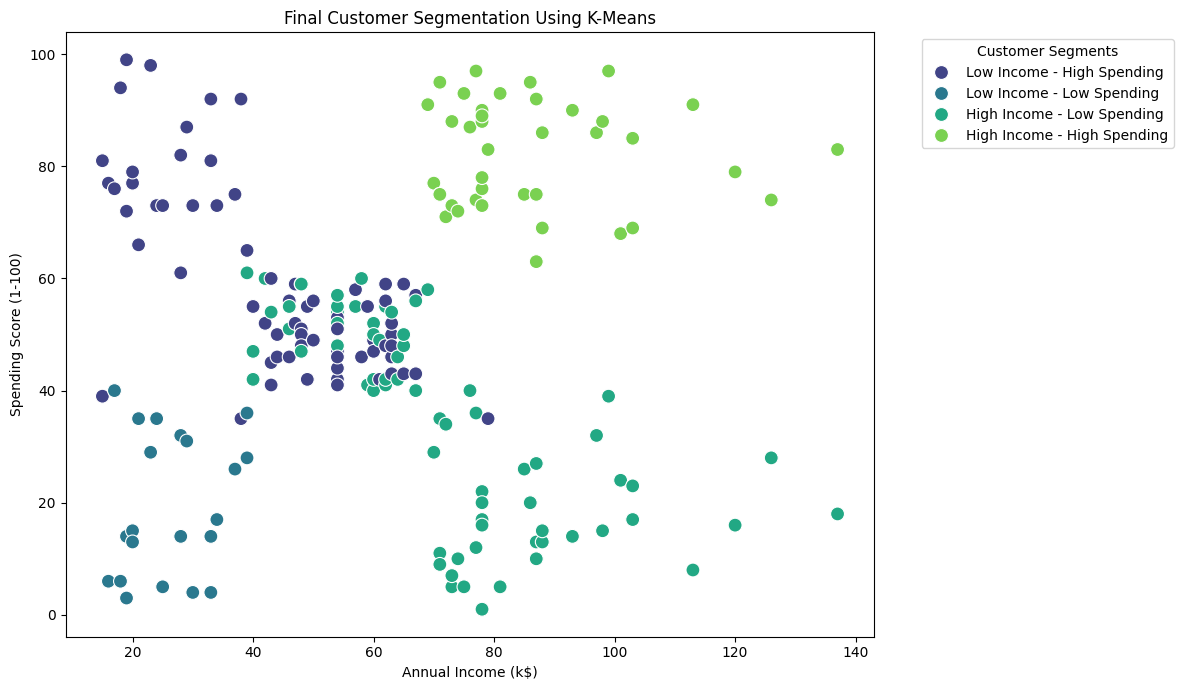

In [59]:
# Create a figure for the final customer segmentation graph
plt.figure(figsize=(12, 7))

# Create a scatter plot using customer segment names
sns.scatterplot(
    data=final_df,
    x='Annual Income (k$)',
    y='Spending Score (1-100)',
    hue='Customer_Segment',
    palette='viridis',
    s=100
)

# Add the graph title
plt.title('Final Customer Segmentation Using K-Means')

# Add labels to the X and Y axes
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')

# Display the legend
plt.legend(title='Customer Segments', bbox_to_anchor=(1.05, 1), loc='upper left')

# Adjust the graph layout
plt.tight_layout()

# Display the final graph
plt.show()

# **step : 13**

In [60]:
# Import joblib to save the trained model and scaler
import joblib

# Save the final K-Means model
joblib.dump(final_kmeans, 'final_kmeans_model.pkl')

# Save the fitted StandardScaler
joblib.dump(scaler, 'customer_scaler.pkl')

# Save the customer segment names
joblib.dump(segment_names, 'segment_names.pkl')

# Display a success message
print("K-Means Model, Scaler, and Segment Names Saved Successfully!")

K-Means Model, Scaler, and Segment Names Saved Successfully!


In [61]:
# Import pandas to create new customer data
import pandas as pd

# Create sample data for new customers
new_customers = pd.DataFrame({
    'Age': [25, 40, 30],
    'Annual Income (k$)': [80, 30, 100],
    'Spending Score (1-100)': [90, 20, 75]
})

# Load the saved StandardScaler
loaded_scaler = joblib.load('customer_scaler.pkl')

# Load the saved K-Means model
loaded_model = joblib.load('final_kmeans_model.pkl')

# Load the saved customer segment names
loaded_segments = joblib.load('segment_names.pkl')

# Scale the new customer data using the existing scaler
new_customers_scaled = loaded_scaler.transform(new_customers)

# Predict the cluster for each new customer
predicted_clusters = loaded_model.predict(new_customers_scaled)

# Add predicted cluster numbers to the new customer data
new_customers['Predicted_Cluster'] = predicted_clusters

# Convert cluster numbers into customer segment names
new_customers['Customer_Segment'] = new_customers['Predicted_Cluster'].map(loaded_segments)

# Display the prediction results
display(new_customers)

,Age,Annual Income (k$),Spending Score (1-100),Predicted_Cluster,Customer_Segment
0,25,80,90,3,High Income - High Spending
1,40,30,20,5,Low Income - Low Spending
2,30,100,75,3,High Income - High Spending


In [62]:
# Import clustering evaluation metrics
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

# Calculate Silhouette Score using scaled data and final cluster labels
final_silhouette = silhouette_score(X_scaled, final_labels)

# Calculate Davies-Bouldin Score
final_db = davies_bouldin_score(X_scaled, final_labels)

# Calculate Calinski-Harabasz Score
final_ch = calinski_harabasz_score(X_scaled, final_labels)

# Display all evaluation scores
print("Final K-Means Model Evaluation")
print("--------------------------------")
print("Best K Value:", best_k)
print("Silhouette Score:", round(final_silhouette, 4))
print("Davies-Bouldin Score:", round(final_db, 4))
print("Calinski-Harabasz Score:", round(final_ch, 4))

Final K-Means Model Evaluation
--------------------------------
Best K Value: 6
Silhouette Score: 0.4284
Davies-Bouldin Score: 0.8254
Calinski-Harabasz Score: 135.1021


# **Deply code**

In [63]:

# Import required libraries
import gradio as gr
import joblib
import pandas as pd

# Load the saved K-Means model
loaded_model = joblib.load("final_kmeans_model.pkl")

# Load the fitted StandardScaler
loaded_scaler = joblib.load("customer_scaler.pkl")

# Load the customer segment names
loaded_segments = joblib.load("segment_names.pkl")


# Define the customer prediction function
def predict_customer(age, annual_income, spending_score):

    # Validate customer input values
    if age is None or annual_income is None or spending_score is None:
        return "Please enter all customer details."

    if age <= 0 or annual_income <= 0:
        return "Age and Annual Income must be greater than zero."

    if spending_score < 1 or spending_score > 100:
        return "Spending Score must be between 1 and 100."

    # Create a DataFrame using the same feature names and order
    new_customer = pd.DataFrame({
        "Age": [age],
        "Annual Income (k$)": [annual_income],
        "Spending Score (1-100)": [spending_score]
    })

    # Scale the customer data using the saved scaler
    scaled_customer = loaded_scaler.transform(new_customer)

    # Predict the customer's cluster
    predicted_cluster = loaded_model.predict(scaled_customer)[0]

    # Get the customer segment name
    segment_name = loaded_segments.get(
        int(predicted_cluster),
        "Unknown Segment"
    )

    # Return the prediction result
    return (
        f"Customer Cluster: {predicted_cluster}\n\n"
        f"Customer Segment: {segment_name}"
    )


# Define the project information
about_project = """
#  Mall Customer Segmentation

## Project Overview
Mall Customer Segmentation is an Unsupervised Machine Learning
project that groups customers based on their shopping behavior.

The main goal is to identify different customer groups so that
businesses can understand their customers and improve marketing strategies.

## Dataset Information
- Dataset: Mall Customers Dataset
- Total Records: 200
- Features: 5
- Selected Features:
  1. Age
  2. Annual Income (k$)
  3. Spending Score (1-100)

## Data Preprocessing
- Data Cleaning
- Exploratory Data Analysis (EDA)
- Feature Selection
- Feature Scaling using StandardScaler

## Machine Learning Algorithms
The project explores these clustering algorithms:

1. K-Means Clustering
2. Hierarchical Clustering
3. DBSCAN
4. Mean Shift
5. Gaussian Mixture Model (GMM)

## Final Model
K-Means Clustering

The final K-Means model uses the selected K value obtained
during model evaluation.

## Evaluation Metrics
- Silhouette Score
- Davies-Bouldin Score
- Calinski-Harabasz Score

## Technology Used
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn
- Gradio
- Google Colab

## Project Objective
To identify customer groups based on age, annual income,
and spending score to support better business decisions.
"""


# Define the contact information
contact_info = """
#  Contact

For questions, feedback, or project-related discussions:

**Email:** piyalbaray314@gmil.com

**Project:** Mall Customer Segmentation

Thank you for visiting my project!
"""


# Create custom CSS for the application
custom_css = """
.gradio-container {
    max-width: 1100px !important;
    margin: auto !important;
}

#main-title {
    text-align: center;
}

#predict-button {
    background: #15803d;
    color: white;
    font-weight: bold;
}
"""


# Create the Gradio application using Blocks
with gr.Blocks(
    theme=gr.themes.Soft(),
    css=custom_css,
    title="Mall Customer Segmentation"
) as demo:

    # Display the application heading
    gr.Markdown(
        """
        <div id="main-title">

        #  Mall Customer Segmentation

        ### AI-Powered Customer Segmentation System

        Discover customer groups using Machine Learning.

        </div>
        """
    )

    # Create navigation tabs
    with gr.Tabs():

        # Home tab
        with gr.Tab(" Home"):
            gr.Markdown(
                """
                ## Customer Segmentation Prediction

                Enter customer details below to predict the
                customer's group using the trained K-Means model.
                """
            )

            # Create three input fields
            age_input = gr.Number(
                label="Age",
                placeholder="Enter customer age",
                precision=0
            )

            income_input = gr.Number(
                label="Annual Income (k$)",
                placeholder="Enter annual income"
            )

            spending_input = gr.Number(
                label="Spending Score (1-100)",
                placeholder="Enter spending score",
                precision=0
            )

            # Create the prediction button
            predict_button = gr.Button(
                " Predict Customer Segment",
                elem_id="predict-button"
            )

            # Create the prediction output area
            prediction_output = gr.Textbox(
                label="Prediction Result",
                lines=4,
                interactive=False
            )

            # Connect the button to the prediction function
            predict_button.click(
                fn=predict_customer,
                inputs=[
                    age_input,
                    income_input,
                    spending_input
                ],
                outputs=prediction_output
            )

            # Create a clear button
            clear_button = gr.ClearButton(
                components=[
                    age_input,
                    income_input,
                    spending_input,
                    prediction_output
                ],
                value="Clear"
            )

        # About tab
        with gr.Tab(" About Project"):

            gr.Markdown(about_project)

        # Contact tab
        with gr.Tab(" Contact"):

            gr.Markdown(contact_info)


# Launch the Gradio application
demo.launch(share=True)


* Running on local URL:  http://127.0.0.1:7860
* Running on public URL: https://b913e5b58ae4a5a77e.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
